In [1]:
# If TensorFlow is not installed, uncomment the next line and run it once.
%pip install tensorflow matplotlib

import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras import layers, models, regularizers

print("Libraries imported successfully!")


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


   ---------------------------------------- 0.0/384.1 MB ? eta -:--:--
   ---------------------------------------- 1.6/384.1 MB 7.8 MB/s eta 0:00:50
   ---------------------------------------- 3.4/384.1 MB 7.5 MB/s eta 0:00:51
   ---------------------------------------- 4.7/384.1 MB 7.4 MB/s eta 0:00:51
    --------------------------------------- 6.3/384.1 MB 7.5 MB/s eta 0:00:51
    --------------------------------------- 8.1/384.1 MB 7.7 MB/s eta 0:00:50
   - -------------------------------------- 9.7/384.1 MB 7.7 MB/s eta 0:00:49
   - -------------------------------------- 11.5/384.1 MB 7.9 MB/s eta 0:00:48
   - -------------------------------------- 13.4/384.1 MB 8.0 MB/s eta 0:00:47
   - -------------------------------------- 14.9/384.1 MB 8.0 MB/s eta 0:00:47
   - -------------------------------------- 16.8/384.1 MB 8.0 MB/s eta 0:00:46
   - -------------------------------------- 18.6/384.1 MB 8.1 MB/s eta 0:00:46
   -- ------------------------------------- 19.9/384.1 MB 8.0 MB/s

In [2]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

print("Training images:", x_train.shape)
print("Testing images :", x_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Training images: (60000, 28, 28)
Testing images : (10000, 28, 28)


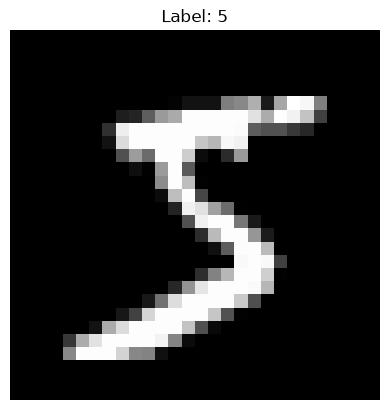

In [3]:
plt.imshow(x_train[0], cmap="gray")
plt.title(f"Label: {y_train[0]}")
plt.axis("off")
plt.show()

In [4]:
x_train = x_train / 255.0
x_test = x_test / 255.0

In [5]:
x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

print("Training data after flattening:", x_train.shape)
print("Testing data after flattening :", x_test.shape)

Training data after flattening: (60000, 784)
Testing data after flattening : (10000, 784)


In [6]:
model_without_reg = models.Sequential([
    layers.Input(shape=(784,)),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax")
])

model_without_reg.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_without_reg.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
history_without_reg = model_without_reg.fit(
    x_train,
    y_train,
    epochs=10,
    validation_split=0.2
)

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9217 - loss: 0.2645 - val_accuracy: 0.9570 - val_loss: 0.1436
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9666 - loss: 0.1104 - val_accuracy: 0.9635 - val_loss: 0.1164
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9772 - loss: 0.0737 - val_accuracy: 0.9670 - val_loss: 0.1087
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9837 - loss: 0.0532 - val_accuracy: 0.9673 - val_loss: 0.1084
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9876 - loss: 0.0393 - val_accuracy: 0.9714 - val_loss: 0.1046
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9895 - loss: 0.0330 - val_accuracy: 0.9699 - val_loss: 0.1156
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9917 - loss: 0.0260 - val_accuracy: 0.9710 - val_loss: 0.1172
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9933 - loss: 0.0206 - 

In [8]:
test_loss, test_accuracy = model_without_reg.evaluate(
    x_test,
    y_test,
    verbose=0
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

Test Loss: 0.10339880734682083
Test Accuracy: 0.9747999906539917


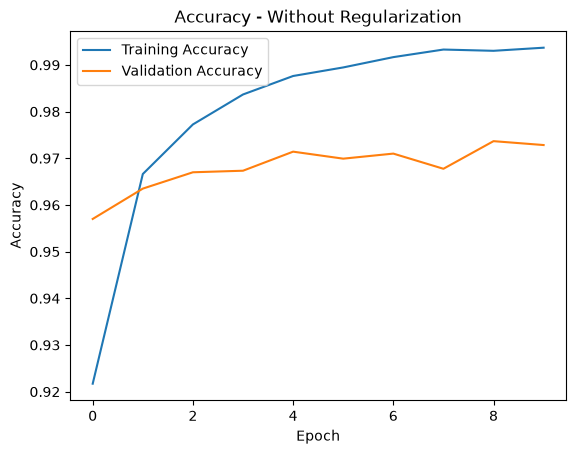

In [9]:
plt.plot(history_without_reg.history["accuracy"], label="Training Accuracy")
plt.plot(history_without_reg.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy - Without Regularization")
plt.legend()
plt.show()

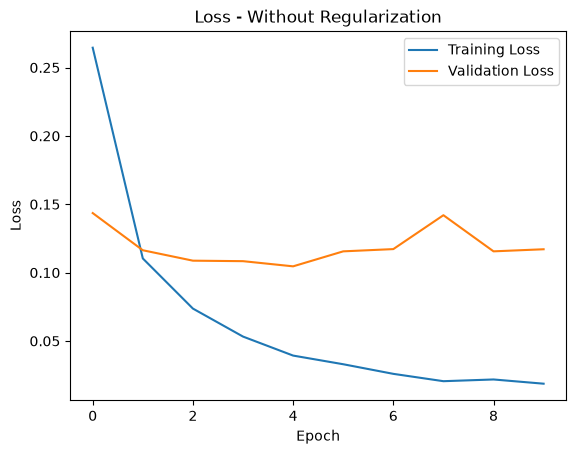

In [10]:
plt.plot(history_without_reg.history["loss"], label="Training Loss")
plt.plot(history_without_reg.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss - Without Regularization")
plt.legend()
plt.show()

In [11]:
model_with_reg = models.Sequential([
    layers.Input(shape=(784,)),

    layers.Dense(
        128,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),
    layers.Dropout(0.3),

    layers.Dense(
        64,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),
    layers.Dropout(0.3),

    layers.Dense(10, activation="softmax")
])

model_with_reg.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_with_reg.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
history_with_reg = model_with_reg.fit(
    x_train,
    y_train,
    epochs=10,
    validation_split=0.2
)

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8659 - loss: 0.6359 - val_accuracy: 0.9448 - val_loss: 0.3545
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9279 - loss: 0.4025 - val_accuracy: 0.9574 - val_loss: 0.2941
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9396 - loss: 0.3488 - val_accuracy: 0.9596 - val_loss: 0.2727
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9432 - loss: 0.3287 - val_accuracy: 0.9640 - val_loss: 0.2521
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9451 - loss: 0.3161 - val_accuracy: 0.9630 - val_loss: 0.2524
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9474 - loss: 0.3050 - val_accuracy: 0.9667 - val_loss: 0.2377
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9488 - loss: 0.2957 - val_accuracy: 0.9643 - val_loss: 0.2382
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9498 - loss: 0.2943 - 

In [13]:
test_loss_reg, test_accuracy_reg = model_with_reg.evaluate(
    x_test,
    y_test,
    verbose=0
)

print("Test Loss:", test_loss_reg)
print("Test Accuracy:", test_accuracy_reg)

Test Loss: 0.22098007798194885
Test Accuracy: 0.9700999855995178


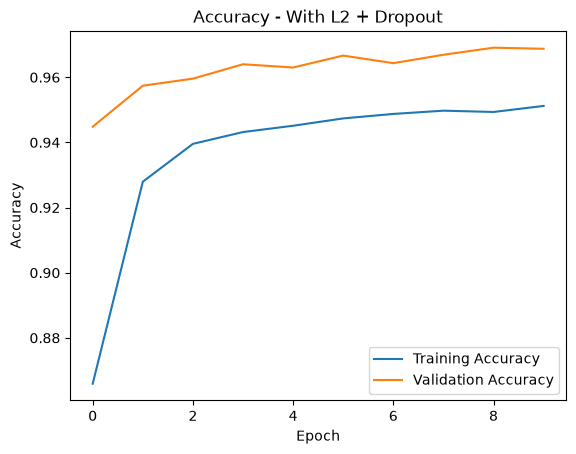

In [14]:
plt.plot(history_with_reg.history["accuracy"], label="Training Accuracy")
plt.plot(history_with_reg.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy - With L2 + Dropout")
plt.legend()
plt.show()

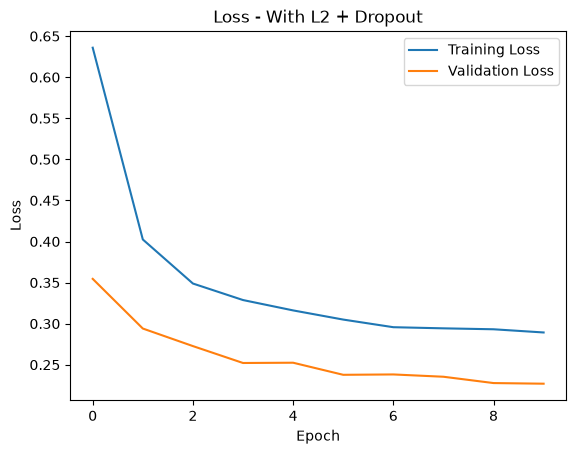

In [15]:
plt.plot(history_with_reg.history["loss"], label="Training Loss")
plt.plot(history_with_reg.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss - With L2 + Dropout")
plt.legend()
plt.show()

In [16]:
print("Model Comparison")
print("=" * 50)

print(f"{'Metric':<20}{'Without Reg.':<15}{'L2 + Dropout':<15}")
print("-" * 50)
print(f"{'Test Accuracy':<20}{test_accuracy:<15.4f}{test_accuracy_reg:<15.4f}")
print(f"{'Test Loss':<20}{test_loss:<15.4f}{test_loss_reg:<15.4f}")

Model Comparison
Metric              Without Reg.   L2 + Dropout   
--------------------------------------------------
Test Accuracy       0.9748         0.9701         
Test Loss           0.1034         0.2210         


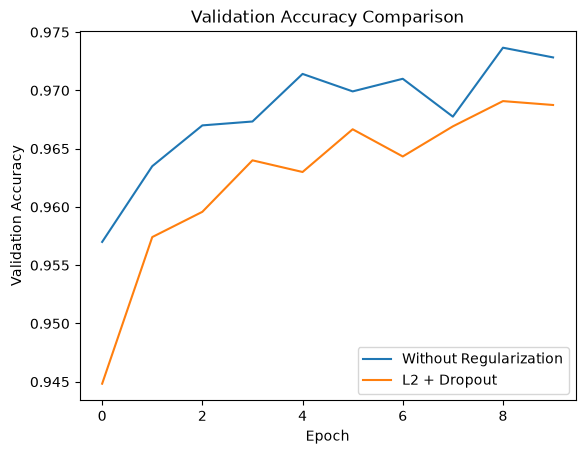

In [17]:
plt.plot(
    history_without_reg.history["val_accuracy"],
    label="Without Regularization"
)

plt.plot(
    history_with_reg.history["val_accuracy"],
    label="L2 + Dropout"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("Validation Accuracy Comparison")
plt.legend()
plt.show()

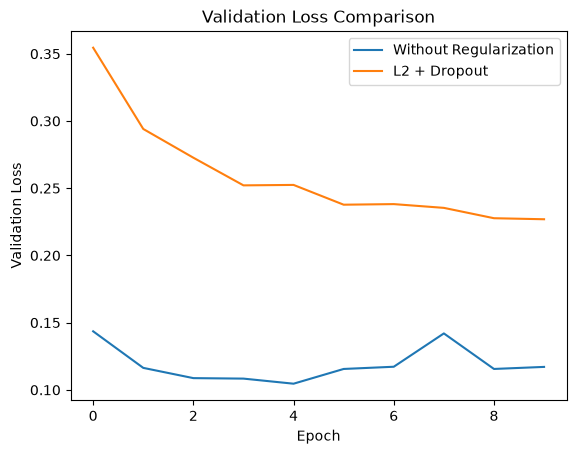

In [18]:
plt.plot(
    history_without_reg.history["val_loss"],
    label="Without Regularization"
)

plt.plot(
    history_with_reg.history["val_loss"],
    label="L2 + Dropout"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Validation Loss Comparison")
plt.legend()
plt.show()